In [2]:
import nltk

# ============================================================
# 1. PREPARAR NLTK
# ============================================================
# Descargar las stopwords de NLTK, que son palabras comunes que se suelen ignorar en el análisis de texto.
nltk.download("stopwords", quiet=True)

# ============================================================
# 2. CREAR NUESTRO CORPUS
# ============================================================
texto = """
the cat sleeps on the sofa
the dog sleeps on the sofa
the cat plays in the garden
the dog plays in the garden
artificial intelligence helps students
artificial intelligence helps teachers
artificial intelligence changes technology
"""

# Separar las palabras
tokens = texto.lower().split()
print("TOKENS:")
print(tokens)

# Convertir el corpus a un objeto NLTK Text
corpus = nltk.Text(tokens)

# ============================================================
# 3. CONCORDANCIA
# ============================================================
print("CONCORDANCIA:")
corpus.concordance("cat", lines=3)

# Contar ocurrencias
print("Frecuencia de cat:", corpus.count("cat"))

# ============================================================
# 4. PALABRAS CON CONTEXTOS SIMILARES
# ============================================================
print("\nPALABRAS SIMILARES:")
corpus.similar("cat")

# ============================================================
# 5. CONTEXTOS COMUNES
# ============================================================
print("\nCONTEXTOS COMUNES:")
corpus.common_contexts(["cat", "dog"])

# ============================================================
# 6. COLOCACIONES
# ============================================================
print("\nCOLOCACIONES:")
corpus.collocations(num=5)

TOKENS:
['the', 'cat', 'sleeps', 'on', 'the', 'sofa', 'the', 'dog', 'sleeps', 'on', 'the', 'sofa', 'the', 'cat', 'plays', 'in', 'the', 'garden', 'the', 'dog', 'plays', 'in', 'the', 'garden', 'artificial', 'intelligence', 'helps', 'students', 'artificial', 'intelligence', 'helps', 'teachers', 'artificial', 'intelligence', 'changes', 'technology']
CONCORDANCIA:
Displaying 2 of 2 matches:
                                  the cat sleeps on the sofa the dog sleeps on 
e sofa the dog sleeps on the sofa the cat plays in the garden the dog plays in 
Frecuencia de cat: 2

PALABRAS SIMILARES:
dog

CONTEXTOS COMUNES:
the_sleeps the_plays

COLOCACIONES:
artificial intelligence; intelligence helps


Frecuencia original:
[('la', 32), (',', 31), ('.', 28), ('y', 23), ('de', 22), ('los', 22)]

Frecuencia filtrada:
[('macondo', 7), ('familia', 6), ('buendía', 6), ('pueblo', 5), ('soledad', 4), ('historia', 4), ('tiempo', 4), ('habitantes', 4), ('años', 3), ('vida', 3)]

Frecuencia absoluta de 'familia': 6
Frecuencia relativa de 'familia': 0.022900763358778626
Total de palabras: 262
Palabras diferentes: 199

Frecuencia de bigramas:
[(('familia', 'buendía'), 3), (('josé', 'arcadio'), 2), (('arcadio', 'buendía'), 2), (('cien', 'años'), 1), (('años', 'soledad'), 1)]

Frecuencia de collocations:
josé arcadio; familia buendía; arcadio buendía
None


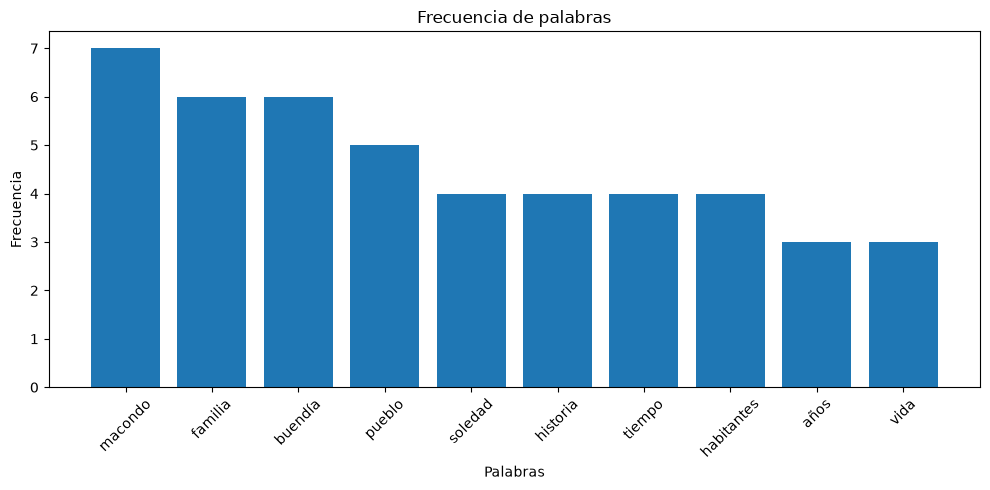

In [15]:
import nltk
import string
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from pathlib import Path
from os import path

# ============================================================
# 1. DESCARGAR STOPWORDS
# ============================================================
nltk.download("stopwords", quiet=True)

# ============================================================
# 2. CREAR CORPUS FROM FILE
# ============================================================
text_path = path.join("data", "cien_anos_de_soledad_resumen.txt")
texto = Path(text_path).read_text(
    encoding="utf-8"
)

# Tokenizar y normalizar a minúsculas
tokens = nltk.wordpunct_tokenize(texto.lower())

# ============================================================
# 3. FRECUENCIA SIN FILTRAR
# ============================================================
fd_original = nltk.FreqDist(tokens)

print("Frecuencia original:")
print(fd_original.most_common(6))

# ============================================================
# 4. ELIMINAR PUNTUACIÓN
# ============================================================
punctuation = set(string.punctuation)

tokens_limpios = [
    word for word in tokens
    if word not in punctuation and word.isalpha()
]

# ============================================================
# 5. ELIMINAR STOPWORDS EN ESPAÑOL
# ============================================================
sw_es = set(stopwords.words("spanish"))

tokens_filtrados = [
    word for word in tokens_limpios
    if word not in sw_es
]

# ============================================================
# 6. FRECUENCIA FINAL
# ============================================================
fd = nltk.FreqDist(tokens_filtrados)

print("\nFrecuencia filtrada:")
print(fd.most_common(10))

print("\nFrecuencia absoluta de 'familia':", fd["familia"])
print("Frecuencia relativa de 'familia':", fd.freq("familia"))
print("Total de palabras:", fd.N())
print("Palabras diferentes:", fd.B())

# ============================================================
# 7. COLLOCATIONS VS BIAGRAMS
# ============================================================
biaggramas = list(nltk.bigrams(tokens_filtrados))
fd_biagramas = nltk.FreqDist(biaggramas)
print("\nFrecuencia de bigramas:")
print(fd_biagramas.most_common(5))

print("\nFrecuencia de collocations:")
corpus = nltk.Text(tokens_filtrados)
print(corpus.collocations(num=5))

# ============================================================
# 8. GRAFICAR FRECUENCIAS
# ============================================================
fig, axes = plt.subplots(figsize=(10, 5))
palabras, frecuencias = zip(*fd.most_common(10))

axes.bar(palabras, frecuencias)
axes.set_ylim(bottom=0)
axes.set_title("Frecuencia de palabras")
axes.set_xlabel("Palabras")
axes.set_ylabel("Frecuencia")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()